# 10 Live decoding

Design: `docs/live_decoding_design.md`. Plan: `docs/live_decoding_plan.md`. This notebook holds the analysis steps of the plan; the code is in `src/` with tests in `tests/`.

**Live rule.** The stage for an epoch uses only signal up to the end of that epoch. It is output a few seconds later (the decision delay), because a beat near the end of an epoch can only be confirmed once a little more signal has arrived. Your decision, 2026-10-24.

## What happened (2026-10-24, run headless)
- **Beat wait (section 1).** Accepting a beat 1 s late already keeps 99.71% of whole-night beats (median of 5 people); 3 s keeps 99.80%. Used: 3 s (an assumption; 1 s also passes the 99.5% rule).
- **Live features (section 2).** All 35 people, past only, saved as `features_causal_all35.csv`. More epochs pass the quality gate live (78.3%) than offline (74.3%). Cause, found afterwards on S102: the pulse-shape check (template_r >= 0.8) passes 90% of epochs with the forward-only filter vs 41% with the offline filter. The threshold was tuned on the offline filter, so the live gate is too lenient. Not fixed.
- **Live vs offline score (section 3).** Same 22 features, same folds. Offline BiGRU: median macro F1 0.488, kappa 0.344. Live forward GRU: 0.459, kappa 0.265. Per person, 29 with REM: macro F1 -0.047 [-0.116, -0.009], kappa -0.091 [-0.148, -0.037], 20 of 29 worse. Live calls more REM (recall 0.506 vs 0.387) and more false REM (0.222 vs 0.128).
- **Streaming decoder (sections 4 and 5).** Same stage as the batch calculation on 100% of 28,189 epochs. 19 ms per epoch (median), 158 KB model, 1.8 GB peak memory, a night in 3 minutes. Time per epoch grows through the night (13 to 25 ms) because interval cleaning reruns over all beats so far. Not fixed.
- **LSL and animation (section 6).** 26 minutes replayed over LSL at 120x: 40 epochs, all equal to batch. `figs/live_replay.gif`: on S014 the live decoder calls REM through most of the last 2.5 hours.


In [1]:
import os
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from config import Config
from recording import Recording
from beats import match_beats
from stream import StreamingBeats
from splits import make_person_folds

DERIVED = ROOT / "data" / "derived"; FIGS = ROOT / "notebooks" / "figs"
DATA_ROOT = Path(os.environ.get("DREAMT_ROOT", ROOT / "data" / "raw"))
LOG = ROOT / "notebooks" / "10_live_progress.log"
plt.rcParams.update({"font.size": 8})
df = pd.read_csv(DERIVED / "features_all35.csv")
people = sorted(df.subject.unique())
folds = make_person_folds(people, n_folds=5, n_tune=4, seed=20261011)
print("people:", len(people))

people: 35


## 1. How long must the live beat detector wait? (plan Task 2, step 5)

**Question.** Live, a beat is only accepted once it is `lag` seconds old, so that later samples can no longer move it. A longer wait gives beats closer to whole-night detection, but every stage comes out later. What is the shortest wait that changes almost nothing?

**Method.** Five people: the first test person of each fold. Whole night. The pulse is filtered forward only (`Config(causal=True)`). Reference: our usual detector run over the whole night in 10-minute chunks (`detect_beats_chunked`), on that same filtered pulse. Live: the same filtered pulse fed 1 s at a time to `StreamingBeats` (30 s buffer), with waits of 1, 2, 3, 5 and 8 s. The detector runs once per second and all five waits are judged from the same detections. Beats are compared inside the scored epochs only, matched within 10 ms.

**Numbers.** Per wait, the median person: share of reference beats the live detector also found, and share of live beats with no reference beat (extra beats). Time per push.

**Figure.** Left: share of reference beats found (y) against the wait (x), one line per person. Right: share of extra live beats. The rule: choose the shortest wait where the median person keeps at least 99.5%.

        % reference beats found (median person)  % live beats with no reference (median person)
wait_s                                                                                         
1.0                                       99.71                                            0.30
2.0                                       99.74                                            0.29
3.0                                       99.80                                            0.30
5.0                                       99.76                                            0.43
8.0                                       99.77                                            0.30

time per push (1 s of signal, 5 waits sharing one detector call): median 6.3 ms
shortest wait with at least 99.5% found: 1.0


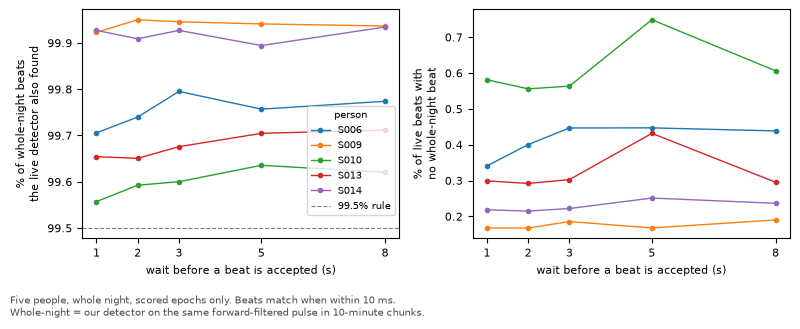

In [2]:
LAGS = [1.0, 2.0, 3.0, 5.0, 8.0]
chosen = [f["test"][0] for f in folds]
LOG.write_text("")
CACHE1 = DERIVED / "live_beat_wait.csv"                 # per-person results; a rerun reads this file
if CACHE1.exists():
    R = pd.read_csv(CACHE1)
else:
    rows = []
    for s in chosen:
        t0 = time.time()
        rec = Recording.load(s, DATA_ROOT, Config(causal=True))
        x = rec.bvp_filt
        ref_t = rec.beat_times                                    # 64 Hz clock, from the whole-night chunked run
        start = max(0, rec.scoring["anchor"] - Config().detect_pre_anchor_s * 64)
        cache = {}
        def shared(buf, cache=cache):                              # one detector call per push, shared by all waits
            if cache.get("k") != cache["n"]:
                try:
                    cache["out"], cache["err"] = StreamingBeats(lag_s=1.0).detector(buf), None
                except Exception as e:
                    cache["out"], cache["err"] = None, e
                cache["k"] = cache["n"]
            if cache["err"] is not None:
                raise cache["err"]
            return cache["out"]
        sbs = {L: StreamingBeats(lag_s=L, buffer_s=30, detector=shared) for L in LAGS}
        got = {L: [] for L in LAGS}
        n_push = 0; t_push = time.time()
        for i in range(start, x.size, 64):
            cache["n"] = n_push
            for L, sb in sbs.items():
                got[L].append(sb.push(x[i:i + 64])[1])
            n_push += 1
        ms = (time.time() - t_push) / n_push * 1000
        for L in LAGS:
            live_t = np.concatenate(got[L]) + start / 64 + rec.t64[0]
            a = ref_t[rec.in_scored(ref_t)]; b = live_t[rec.in_scored(live_t)]
            b = b[b < live_t.max()]; a = a[a <= b.max()]                     # same end: drop the final unconfirmed seconds
            ia, ib = match_beats(a, b, tol=0.01)
            rows.append({"person": s, "wait_s": L, "found": ia.size / a.size, "extra": 1 - ib.size / b.size,
                         "ref_beats": a.size, "ms_per_push": ms})
        with open(LOG, "a") as fh:
            fh.write(f"{s}: {n_push} pushes, {ms:.1f} ms per push, {time.time() - t0:.0f}s\n")
        del rec, x
    R = pd.DataFrame(rows); R.to_csv(CACHE1, index=False)
summ = R.groupby("wait_s")[["found", "extra"]].median()
print((100 * summ).round(2).rename(columns={"found": "% reference beats found (median person)",
                                          "extra": "% live beats with no reference (median person)"}).to_string())
print(f"\ntime per push (1 s of signal, 5 waits sharing one detector call): median {R.ms_per_push.median():.1f} ms")
ok = summ.index[summ.found >= 0.995]
print("shortest wait with at least 99.5% found:", ok.min() if len(ok) else "none")

fig, axs = plt.subplots(1, 2, figsize=(8, 3.2))
for s, g in R.groupby("person"):
    axs[0].plot(g.wait_s, 100 * g.found, marker="o", ms=3, lw=1, label=s)
    axs[1].plot(g.wait_s, 100 * g.extra, marker="o", ms=3, lw=1, label=s)
axs[0].axhline(99.5, color="0.5", ls="--", lw=0.8, label="99.5% rule")
axs[0].set_ylabel("% of whole-night beats\nthe live detector also found"); axs[1].set_ylabel("% of live beats with\nno whole-night beat")
for ax in axs:
    ax.set_xlabel("wait before a beat is accepted (s)"); ax.set_xticks(LAGS)
axs[0].legend(fontsize=7, title="person", title_fontsize=7)
fig.text(0.01, 0.005, "Five people, whole night, scored epochs only. Beats match when within 10 ms.\n"
         "Whole-night = our detector on the same forward-filtered pulse in 10-minute chunks.", fontsize=7, color="0.3")
axs[0].legend(fontsize=7, title="person", title_fontsize=7, loc="lower right", bbox_to_anchor=(1.0, 0.08))
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.savefig(FIGS / "fig10_beat_wait.png", dpi=150); plt.show()

**Decision after section 1.** Wait = 3 s (`Config.live_lag_s`). ASSUMPTION: 3 s was chosen by judgement, not tuned; 1 s also passes the 99.5% rule. Changing it means rebuilding section 2 onwards.

## 2. Features as the live decoder sees them, all 35 people (plan Task 3). HEAVY: about 35 minutes.

**What.** For every scored epoch of every person, the 22 raw features (10 base + 7 heart rate over minutes + 5 nonlinear beat intervals), computed only from the past: forward-filtered pulse, beats from the live detector with the 3 s wait, intervals cleaned against the previous 11, every 5-minute window ending at the epoch end. Code: `src/live_features.py` (assumptions listed at the top of that file), tests in `tests/test_live_features.py`.

**Scaling.** Each column is z-scored with the mean and spread of that person's night so far, including the current epoch (`normalise_per_person(causal=True, min_periods=10)`). ASSUMPTION: as in the offline plan; the first 9 epochs of each night therefore have no z-score and are filled with the training median plus a missing flag by the model.

**Saved.** `data/derived/features_causal_all35.csv` (new file; `features_all35.csv` is untouched). Not in git.

**Checks.** Same (person, epoch) rows as `features_all35.csv`. The file's TIMESTAMP equals sample / 64 (the live code uses sample / 64).

**Number.** Share of epochs passing the quality gate, live vs offline (offline: 20,952 of 28,189 = 74.3%).

**Figure.** One dot per person: offline pass share (x) against live pass share (y); on the dashed line = the same.

TIMESTAMP vs sample/64, S006: largest difference 0.00e+00 s


rows: 28189 | same (person, epoch) keys as features_all35.csv
epochs passing the gate: live 78.3% (22074), offline 74.3% (20952)
missing share of the z columns (first 9 epochs per person plus gated epochs):
hr_mean_z      0.228
motion_z       0.011
hr5_std_z      0.228
nl_sampen_z    0.228


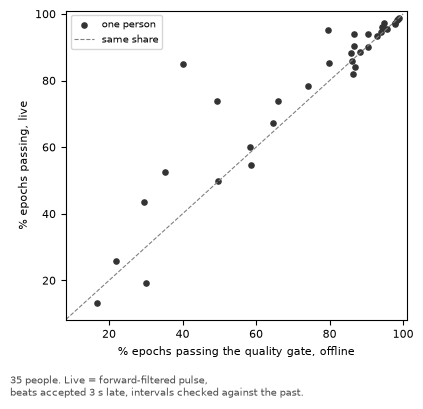

In [3]:
import os
from concurrent.futures import ProcessPoolExecutor
from live_features import RAW_COLS, build_person
from features import normalise_per_person

CFG = Config(causal=True)
r0 = Recording.load(people[0], DATA_ROOT, CFG)
print(f"TIMESTAMP vs sample/64, {people[0]}: largest difference {np.abs(r0.t64 - r0.t64[0] - np.arange(r0.t64.size) / 64).max():.2e} s")
del r0

CAUSAL = DERIVED / "features_causal_all35.csv"
if CAUSAL.exists():
    C = pd.read_csv(CAUSAL, float_precision="round_trip")
else:
    os.environ["PYTHONPATH"] = str(ROOT / "src")                 # spawned workers need src/ on their path
    t0 = time.time(); parts = {}
    with ProcessPoolExecutor(max_workers=3) as ex:
        futs = {s: ex.submit(build_person, s, DATA_ROOT, CFG) for s in people}
        for s, fu in futs.items():
            parts[s] = fu.result()
            with open(LOG, "a") as fh:
                fh.write(f"section 2: {s} done, {time.time() - t0:.0f}s since start\n")
    C = pd.concat([parts[s] for s in people], ignore_index=True)
    Z = normalise_per_person(C, RAW_COLS, causal=True, min_periods=10)
    Z.columns = [c + "_z" for c in RAW_COLS]
    C = pd.concat([C, Z], axis=1)
    C.to_csv(CAUSAL, index=False)
    print(f"built in {time.time() - t0:.0f}s")

key_live = list(zip(C.subject, C.epoch)); key_off = list(zip(df.subject, df.epoch))
assert key_live == key_off, "row keys differ from features_all35.csv"
print("rows:", len(C), "| same (person, epoch) keys as features_all35.csv")
p_live, p_off = C.groupby("subject")["pass"].mean(), df.groupby("subject")["pass"].mean()
print(f"epochs passing the gate: live {C['pass'].mean():.1%} ({int(C['pass'].sum())}), offline {df['pass'].mean():.1%} ({int(df['pass'].sum())})")
print("missing share of the z columns (first 9 epochs per person plus gated epochs):")
print(C[[c + "_z" for c in ["hr_mean", "motion", "hr5_std", "nl_sampen"]]].isna().mean().round(3).to_string())

fig, ax = plt.subplots(figsize=(4.2, 4))
ax.scatter(100 * p_off, 100 * p_live.loc[p_off.index], s=14, color="0.2", label="one person")
ax.plot([0, 100], [0, 100], color="0.5", ls="--", lw=0.8, label="same share")
ax.set_xlabel("% epochs passing the quality gate, offline"); ax.set_ylabel("% epochs passing, live")
lo = 100 * min(p_off.min(), p_live.min()) - 5; ax.set_xlim(lo, 101); ax.set_ylim(lo, 101)
ax.legend(fontsize=7, loc="upper left")
fig.text(0.01, 0.005, "35 people. Live = forward-filtered pulse,\nbeats accepted 3 s late, intervals checked against the past.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.savefig(FIGS / "fig10_gate_live_vs_offline.png", dpi=150); plt.show()

## 3. Live score against offline, all 35 people (plan Task 5). About 6 minutes.

**Two models, same 5 person folds, same settings** (balanced class weights, up to 30 passes, best pass on the 4 validation people, one seed), same 22 features:
- **offline:** the BiGRU (reads the night forwards and backwards) on the offline features: `features_all35.csv` + heart rate over minutes + nonlinear beat intervals, all z-scored over the whole night. Saved `preds_bigru_offline22_5fold.csv`.
- **live:** a forward-only GRU on the live features from section 2 (`features_causal_all35.csv`, z-scored with the night so far). Saved `preds_live_5fold.csv`; each fold's model saved to `data/derived/models/live_fold<i>.pt` with its feature names and training medians.

ASSUMPTIONS: the live model is trained on live features (what it will see), not on offline ones. Missing values are filled with the training median of that fold, plus a missing flag, in both models.

**Numbers.** A table for all 35 and for the 29 with REM. The paired change per person, live minus offline, in macro F1 and in kappa, on the 29 with REM, with the bootstrap 95% interval. The "no guess" share (epochs failing the live quality gate) and the live macro F1 on the other epochs only.

**Figure.** One dot per person: offline macro F1 (x) against live macro F1 (y). Filled = had REM, open = no REM. Below the dashed line = worse live.

trained in 220s
                                           median_macro_f1  kappa_pooled  rem_f1  rem_recall  false_rem_on_nrem
people      run                                                                                                
all 35      offline (BiGRU, whole night)             0.488         0.344   0.314       0.387              0.128
            live (forward GRU, past only)            0.459         0.265   0.302       0.506              0.222
29 with REM offline (BiGRU, whole night)             0.478         0.329   0.321       0.387              0.140
            live (forward GRU, past only)            0.459         0.246   0.323       0.506              0.228

per person, 29 with REM, live minus offline:


/var/folders/2k/048tkd090q57zrdyymtr6l1m0000gn/T/ipykernel_5608/1252343744.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby("subject").apply(lambda g: cohen_kappa_score(g.y, g.yhat) if g.y.nunique() > 1 else np.nan)
/var/folders/2k/048tkd090q57zrdyymtr6l1m0000gn/T/ipykernel_5608/1252343744.py:42: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return p.groupby("subject").apply(lambda g: cohen_kappa

  macro F1  median -0.047  95% CI [-0.116, -0.009]  better 9 / worse 20
  kappa     median -0.091  95% CI [-0.148, -0.037]  better 9 / worse 20

'no guess' share (live quality gate fails): 21.7%
live median macro F1 on guessed epochs only: 0.434 (all epochs: 0.459)


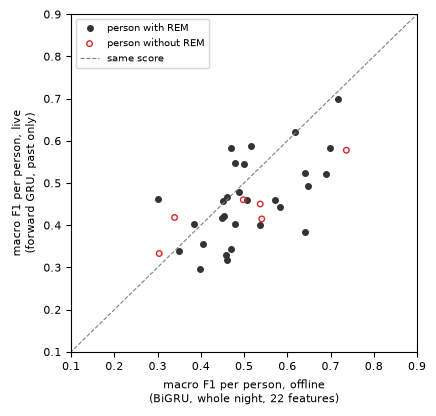

In [4]:
import warnings
from sklearn.metrics import cohen_kappa_score, f1_score
from evaluation import make_xy, macro_f1_per_person, rem_rates, model_for
from metrics import paired_difference
from sequence import BiGRUSequence, make_sequences
from groups import build_group

MODELS = DERIVED / "models"; MODELS.mkdir(exist_ok=True)
had_rem = df.groupby("subject").stage3.agg(lambda x: (x == "REM").any())
with_rem = list(had_rem[had_rem].index)
fam = [build_group(n, None, True, people, None, df, DERIVED) for n in ["hrmin", "nonlin"]]   # cached files
D_off = df.join([g[[c for c in g.columns if c.endswith("_z")]] for g in fam])
COLS = [c + "_z" for c in RAW_COLS]
assert all(c in D_off.columns for c in COLS) and all(c in C.columns for c in COLS)
D_live = C.copy(); D_live.index = df.index                       # same rows, same order (checked in section 2)

def run(D, causal, name, save_models=False):
    X, y, s, idx = make_xy(D, COLS)
    ep = D.loc[idx, "epoch"].to_numpy(); parts = []
    for i, f in enumerate(folds):
        tr = np.isin(s, f["train"])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            med = np.nanmedian(X[tr], axis=0)
        med = np.where(np.isnan(med), 0.0, med)
        seq = {q["subject"]: q for q in make_sequences(X, y, s, idx, ep, med)}
        m = BiGRUSequence(weighting="balanced", causal=causal).fit([seq[q] for q in f["train"]], [seq[q] for q in f["tune"]])
        if save_models:
            m.save(MODELS / f"live_fold{i}.pt", extra={"cols": COLS, "medians": med.tolist(), "fold": i})
        test = [seq[q] for q in f["test"]]
        for q, yh in zip(test, m.predict(test)):
            parts.append(pd.DataFrame({"subject": q["subject"], "row": q["row"], "y": q["y"], "yhat": yh, "fold": i}))
    p = pd.concat(parts, ignore_index=True); p.to_csv(DERIVED / f"{name}.csv", index=False)
    return p

def summary(p):
    t = macro_f1_per_person(p); rr, fr = rem_rates(p)
    return {"median_macro_f1": t.macro_f1.median(), "kappa_pooled": cohen_kappa_score(p.y, p.yhat),
            "rem_f1": f1_score(p.y, p.yhat, labels=[2], average="macro"), "rem_recall": rr, "false_rem_on_nrem": fr}

def kappa_per_person(p):
    return p.groupby("subject").apply(lambda g: cohen_kappa_score(g.y, g.yhat) if g.y.nunique() > 1 else np.nan)

t0 = time.time()
P_off = run(D_off, False, "preds_bigru_offline22_5fold")
P_live = run(D_live, True, "preds_live_5fold", save_models=True)
print(f"trained in {time.time() - t0:.0f}s")
rows = []
for who, keep in [("all 35", people), ("29 with REM", with_rem)]:
    for label, p in [("offline (BiGRU, whole night)", P_off), ("live (forward GRU, past only)", P_live)]:
        rows.append({"people": who, "run": label, **summary(p[p.subject.isin(keep)])})
print(pd.DataFrame(rows).set_index(["people", "run"]).round(3).to_string())

F_off = macro_f1_per_person(P_off).macro_f1; F_live = macro_f1_per_person(P_live).macro_f1
K_off = kappa_per_person(P_off); K_live = kappa_per_person(P_live)
print("\nper person, 29 with REM, live minus offline:")
for nm, a, b in [("macro F1", F_live, F_off), ("kappa", K_live, K_off)]:
    a, b = a[with_rem], b[with_rem]
    d = paired_difference(a, b); dl = (a - b).dropna()
    print(f"  {nm:9s} median {d['median']:+.3f}  95% CI [{d['lo']:+.3f}, {d['hi']:+.3f}]  better {int((dl > 0).sum())} / worse {int((dl < 0).sum())}")
gate = D_live.loc[P_live.row, "pass"].to_numpy(bool)
print(f"\n'no guess' share (live quality gate fails): {1 - gate.mean():.1%}")
pg = P_live[gate]
print(f"live median macro F1 on guessed epochs only: {macro_f1_per_person(pg).macro_f1.median():.3f} "
      f"(all epochs: {F_live.median():.3f})")

fig, ax = plt.subplots(figsize=(4.4, 4.2))
r = had_rem.loc[F_off.index].to_numpy()
ax.scatter(F_off[r], F_live[F_off.index][r], s=16, color="0.2", label="person with REM")
ax.scatter(F_off[~r], F_live[F_off.index][~r], s=16, facecolor="none", edgecolor="tab:red", label="person without REM")
ax.plot([0, 1], [0, 1], color="0.5", ls="--", lw=0.8, label="same score")
ax.set_xlabel("macro F1 per person, offline\n(BiGRU, whole night, 22 features)"); ax.set_ylabel("macro F1 per person, live\n(forward GRU, past only)")
ax.set_xlim(0.1, 0.9); ax.set_ylim(0.1, 0.9); ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig(FIGS / "fig10_live_vs_offline.png", dpi=150); plt.show()

## 4. The streaming decoder on one real night (plan Task 6). About 5 minutes.

**What.** One person's whole night fed to `LiveDecoder` (`src/live.py`, assumptions at the top of that file) in 1 s chunks from the first sample of the file, decoded by the fold model that never saw them. This is the real streaming path: forward filter state carried between chunks, the live beat detector, a 2-minute window of recent signal, running z-scores, and one model step per epoch.

**Check.** It should give exactly the features of section 2 and the stages of section 3 for this person. Any difference is a bug.

**Numbers.** Share of epochs with the same stage as `preds_live_5fold.csv`; the largest feature difference from `features_causal_all35.csv`; time per epoch.

**Figure.** Time to decode each epoch through the night (ms), with the median as a line.

S014: 796 epochs decoded in 166s for 8.0 h of signal
same stage as the batch run (section 3): 100.00% of 796 epochs
largest feature difference from section 2: 5.78e-12; missing in one but not the other: 0
ms per epoch: median 18.2, 95th percentile 24.1, max 25.9


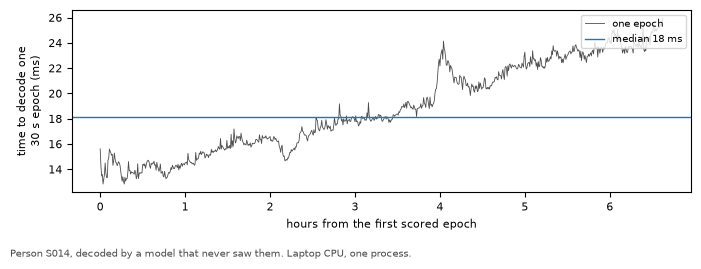

In [5]:
from live import run_night, STREAM_COLS
P1 = folds[0]["test"][0]
t0 = time.time()
R1, info1 = run_night(P1, DATA_ROOT, CFG, MODELS / f"live_fold{model_for(P1, folds)}.pt")
print(f"{P1}: {len(R1)} epochs decoded in {time.time() - t0:.0f}s for {info1['seconds_of_signal'] / 3600:.1f} h of signal")
rows1 = df.index[df.subject == P1]
batch_stage = P_live.set_index("row").yhat.reindex(rows1).to_numpy()
live_stage = R1.stage.map({"W": 0, "NREM": 1, "REM": 2}).to_numpy()
assert len(live_stage) == len(rows1)
print(f"same stage as the batch run (section 3): {np.mean(live_stage == batch_stage):.2%} of {len(rows1)} epochs")
diff = (R1[[f"raw_{c}" for c in RAW_COLS]].to_numpy() - C.loc[rows1, RAW_COLS].to_numpy())
print(f"largest feature difference from section 2: {np.nanmax(np.abs(diff)):.2e}; "
      f"missing in one but not the other: {int((np.isnan(diff) & ~(np.isnan(R1[[f'raw_{c}' for c in RAW_COLS]].to_numpy()) & np.isnan(C.loc[rows1, RAW_COLS].to_numpy()))).sum())}")
print(f"ms per epoch: median {R1.ms.median():.1f}, 95th percentile {R1.ms.quantile(0.95):.1f}, max {R1.ms.max():.1f}")

fig, ax = plt.subplots(figsize=(7, 2.6))
hrs = np.arange(len(R1)) * 30 / 3600
ax.plot(hrs, R1.ms, color="0.3", lw=0.6, label="one epoch")
ax.axhline(R1.ms.median(), color="tab:blue", lw=1, label=f"median {R1.ms.median():.0f} ms")
ax.set_xlabel("hours from the first scored epoch"); ax.set_ylabel("time to decode one\n30 s epoch (ms)")
ax.legend(fontsize=7, loc="upper right")
fig.text(0.01, 0.005, f"Person {P1}, decoded by a model that never saw them. Laptop CPU, one process.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.savefig(FIGS / "fig10_ms_per_epoch_one_night.png", dpi=150); plt.show()

## 5. Product numbers, all 35 nights through the streaming decoder (plan Task 7). HEAVY: about 45 minutes.

**What.** Every person's whole night through `LiveDecoder`, each with the fold model that never saw them, 3 nights at a time in separate processes, as fast as the computer allows (no real-time waiting).

**Numbers.** Time per epoch (median and 95th percentile), the model file size, the largest memory one process reached, the "no guess" share, and the share of epochs where streaming and batch give the same stage (all 35).

**Figure.** Histogram of time per epoch, all nights pooled, with the median and 95th percentile marked.

time per epoch: median 18.7 ms, 95th percentile 27.3 ms, max 39 ms
model file: 158 KB | largest memory of one process: 1783 MB
'no guess' share: 21.7% | streaming = batch stage: 100.00% of 28189 epochs
a whole night takes 3.0 min to decode at full speed (median), 179x faster than real time


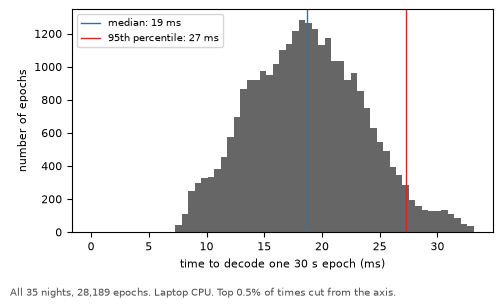

In [6]:
CACHE5 = DERIVED / "live_stream_all35.csv"
if CACHE5.exists():
    RA = pd.read_csv(CACHE5); INFO = pd.read_csv(DERIVED / "live_stream_all35_info.csv")
else:
    os.environ["PYTHONPATH"] = str(ROOT / "src")
    t0 = time.time(); res = {}
    with ProcessPoolExecutor(max_workers=3) as ex:
        futs = {s: ex.submit(run_night, s, DATA_ROOT, CFG, MODELS / f"live_fold{model_for(s, folds)}.pt") for s in people}
        for s, fu in futs.items():
            res[s] = fu.result()
            with open(LOG, "a") as fh:
                fh.write(f"section 5: {s} done, {time.time() - t0:.0f}s since start\n")
    RA = pd.concat([res[s][0] for s in people], ignore_index=True); INFO = pd.DataFrame([res[s][1] for s in people])
    RA.to_csv(CACHE5, index=False); INFO.to_csv(DERIVED / "live_stream_all35_info.csv", index=False)
RA.index = df.index                                              # one row per scored epoch, same order
same = RA.stage.map({"W": 0, "NREM": 1, "REM": 2}).to_numpy() == P_live.set_index("row").yhat.reindex(df.index).to_numpy()
size_kb = (MODELS / "live_fold0.pt").stat().st_size / 1024
print(f"time per epoch: median {RA.ms.median():.1f} ms, 95th percentile {RA.ms.quantile(0.95):.1f} ms, max {RA.ms.max():.0f} ms")
print(f"model file: {size_kb:.0f} KB | largest memory of one process: {INFO.peak_mb_worker.max():.0f} MB")
print(f"'no guess' share: {RA.abstain.mean():.1%} | streaming = batch stage: {same.mean():.2%} of {len(same)} epochs")
print(f"a whole night takes {INFO.wall_s.median() / 60:.1f} min to decode at full speed (median), "
      f"{INFO.seconds_of_signal.median() / INFO.wall_s.median():.0f}x faster than real time")

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(RA.ms, bins=np.linspace(0, RA.ms.quantile(0.995), 60), color="0.4")
for q, lab, c in [(0.5, "median", "tab:blue"), (0.95, "95th percentile", "tab:red")]:
    v = RA.ms.quantile(q); ax.axvline(v, color=c, lw=1, label=f"{lab}: {v:.0f} ms")
ax.set_xlabel("time to decode one 30 s epoch (ms)"); ax.set_ylabel("number of epochs")
ax.legend(fontsize=7)
fig.text(0.01, 0.005, "All 35 nights, 28,189 epochs. Laptop CPU. Top 0.5% of times cut from the axis.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.savefig(FIGS / "fig10_ms_per_epoch_all.png", dpi=150); plt.show()

## 6. Over LSL, and the replay animation (plan Task 8)

**LSL.** `scripts/live_demo.py` sends 20 minutes of one test person's night over LSL at 120x real time, and decodes what arrives with `LiveDecoder`. It prints one line per epoch and the agreement with the batch run. ASSUMPTION (stated in the script): to save time the replay starts 60 s before the beat detector's start, not at the start of the file, so a few early epochs may differ slightly.

**Animation.** The person from section 4, whole night: the expert's stages on top, the live stages filling in below, epochs with "no guess" in grey. Saved as `notebooks/figs/live_replay.gif`.

In [7]:
import subprocess
out = subprocess.run([sys.executable, str(ROOT / "scripts" / "live_demo.py"), "--person", P1, "--minutes", "20", "--speed", "120"],
                     capture_output=True, text=True, timeout=900)
lines = out.stdout.strip().splitlines()
print("\n".join(lines[:4] + ["  ..."] + lines[-3:]))
if out.returncode: print(out.stderr[-2000:])

S014: decoded by fold 0's model, which never saw this person. Replaying 26.1 min at 120x over LSL.
  epoch    0  W                    16.1 ms
  epoch    1  no guess (W)         14.2 ms
  epoch    2  W                    13.2 ms
  ...
  epoch   38  NREM                 14.5 ms
  epoch   39  NREM                 14.5 ms
received 100096 of 100160 samples | decoded 40 epochs | same stage as the batch-causal run: 100.0% of 40


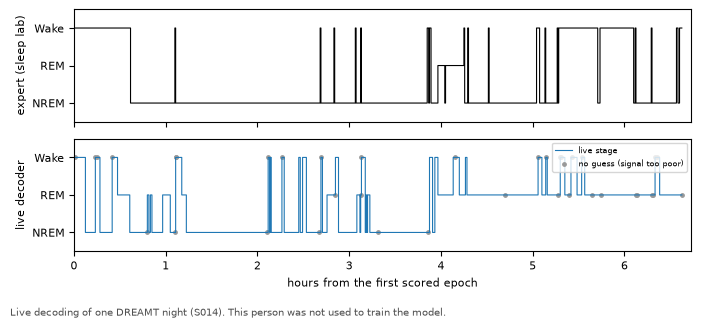

frames: 100 | saved figs/live_replay.gif


In [8]:
from matplotlib.animation import FuncAnimation, PillowWriter
truth = df.loc[rows1, "stage3"].map({"W": 2, "REM": 1, "NREM": 0}).to_numpy()
live = R1.stage.map({"W": 2, "REM": 1, "NREM": 0}).to_numpy(); nog = R1.abstain.to_numpy()
hrs = np.arange(len(truth)) * 30 / 3600
fig, axs = plt.subplots(2, 1, figsize=(7, 3.2), sharex=True)
for ax, ttl in zip(axs, ["expert (sleep lab)", "live decoder"]):
    ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["NREM", "REM", "Wake"]); ax.set_ylim(-0.5, 2.5); ax.set_ylabel(ttl)
axs[0].step(hrs, truth, where="post", color="k", lw=0.8)
axs[1].set_xlim(0, hrs[-1] + 0.1); axs[1].set_xlabel("hours from the first scored epoch")
line, = axs[1].step([], [], where="post", color="tab:blue", lw=0.8, label="live stage")
grey = axs[1].scatter([], [], s=6, color="0.6", label="no guess (signal too poor)")
axs[1].legend(fontsize=6, loc="upper right")
fig.text(0.01, 0.005, f"Live decoding of one DREAMT night ({P1}). This person was not used to train the model.", fontsize=7, color="0.3")
plt.tight_layout(rect=(0, 0.05, 1, 1))
step = 8
def draw(i):
    j = min(len(live), (i + 1) * step)
    line.set_data(hrs[:j], live[:j])
    g = np.flatnonzero(nog[:j]); grey.set_offsets(np.c_[hrs[g], live[g]] if g.size else np.empty((0, 2)))
    return line, grey
anim = FuncAnimation(fig, draw, frames=int(np.ceil(len(live) / step)), blit=True)
anim.save(FIGS / "live_replay.gif", writer=PillowWriter(fps=20))
draw(10 ** 9); plt.savefig(FIGS / "fig10_live_replay_last_frame.png", dpi=150); plt.show()
print("frames:", int(np.ceil(len(live) / step)), "| saved figs/live_replay.gif")